# 01. Tokenization and pretrained embeddings

**Questions:** BPE or word-level? How large a vocabulary? Which pretrained model should I use?

**Already known from the EDA:** with equal rows, word beat BPE by 0.08–0.09 in every fold. BPE removes unknown tokens but predicts fragments such as `Ста`. However, that test used a 16k vocabulary and random embeddings. About 40% of mentions contain an unknown word, so a bigger vocabulary or subword information could change the answer. Only this part is new here.

**About "pretrained RNN-like models":** the assignment's request here is pretrained **embeddings** used to initialize or feed your own GRU/LSTM, and that's what this notebook tests:

| Option | What it is | Status |
| --- | --- | --- |
| fastText aligned | Ukrainian and russian in one shared space, lowercase, 912k Ukrainian words | Tested here |
| fastText crawl | Larger corpus, each language in a separate space | Tested here |
| Flair `lang-uk/flair-uk-forward` | A truly pretrained character LSTM, Ukrainian only and marked work in progress | Not tested; slow, consider only if fastText leaves a big gap |
| Stanza Ukrainian NER (`languk`) | A pretrained tagger with different labels | Not tested; could be a comparison, but it isn't your model |

Transformers such as BERT are banned by the assignment. Vectors are streamed, so only the top 200k words per language are read (about 1 GB in total for aligned), then cached.

All runs use the same rows on fold 0; change the shared settings in `nerkit/decisions.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "eda").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "model")]

import pandas as pd
from IPython.display import display

from nerkit import plots
from nerkit.config import SEEDS
from nerkit.data import load_rows, load_test, split_fold, split_inner
from nerkit.decisions import base_config
from nerkit.diagnostics import unknown_rates, window_statistics
from nerkit.embeddings import embedding_matrix, load_vectors
from nerkit.experiment import records_named, run_grid, summarize, top_names
from nerkit.tokenization import fit_tokenizer

NOTEBOOK = "01_tokenization_embeddings"
rows = load_rows(("cv",))
test_rows = load_test()
training, heldout = split_fold(rows, 0)
fit_rows, _ = split_inner(training)

## 1. Coverage, with no training
Lower unknown rates are good, but the EDA showed they don't guarantee better F1. Competition posts are used for measurement only and are never fitted.

In [2]:
coverage = []
texts = [r["text"] for r in fit_rows]
for label, options in {
    "word 16k": dict(kind="word", vocab_size=16_000),
    "word 50k": dict(kind="word", vocab_size=50_000),
    "word 100k": dict(kind="word", vocab_size=100_000),
    "word 16k lowercase": dict(kind="word", vocab_size=16_000, lowercase=True),
    "word 50k lowercase": dict(kind="word", vocab_size=50_000, lowercase=True),
    "bpe 16k": dict(kind="bpe", vocab_size=16_000),
    "bpe 32k": dict(kind="bpe", vocab_size=32_000),
}.items():
    tokenizer = fit_tokenizer(texts, **options)
    coverage.append(dict(tokenizer=label, actual_vocabulary=tokenizer.get_vocab_size(),
                         **unknown_rates(tokenizer, heldout, test_rows),
                         **window_statistics(tokenizer, test_rows)))
display(pd.DataFrame(coverage).round(3))

,tokenizer,actual_vocabulary,uk_mentions_unknown,ru_mentions_unknown,test_tokens_unknown,test_tokens_per_post,posts,over_256,longest
0,word 16k,16000,0.398,0.386,0.302,68.281,477,13,591
1,word 50k,50000,0.281,0.284,0.211,68.281,477,13,591
2,word 100k,100000,0.207,0.220,0.175,68.281,477,13,591
3,word 16k lowercase,16000,0.393,0.394,0.275,68.281,477,13,591
4,word 50k lowercase,50000,0.266,0.274,0.186,68.281,477,13,591
5,bpe 16k,16000,0.000,0.000,0.024,104.985,477,36,912
6,bpe 32k,32000,0.000,0.000,0.027,95.195,477,31,800


## 2. Coverage with pretrained vocabulary
The first run streams the vectors. Words from the pretrained table join the vocabulary without any use of competition text.

In [3]:
config = base_config()
pretrained_coverage = []
for name in ("aligned", "crawl"):
    words, vectors = load_vectors(name, config.pretrained_top_k)
    tokenizer = fit_tokenizer(texts, "word", 16_000, lowercase=True, extra_words=words)
    _, known = embedding_matrix(tokenizer, words, vectors, config.seed)
    pretrained_coverage.append(dict(vectors=name, words=len(words), vocabulary=tokenizer.get_vocab_size(),
                                    vocabulary_with_vector=known.mean(), **unknown_rates(tokenizer, heldout, test_rows)))
display(pd.DataFrame(pretrained_coverage).round(3))

Reading the top 200,000 words from https://dl.fbaipublicfiles.com/fasttext/vectors-aligned/wiki.uk.align.vec
Reading the top 200,000 words from https://dl.fbaipublicfiles.com/fasttext/vectors-aligned/wiki.ru.align.vec
Reading the top 200,000 words from https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.uk.300.vec.gz
Reading the top 200,000 words from https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ru.300.vec.gz


,vectors,words,vocabulary,vocabulary_with_vector,uk_mentions_unknown,ru_mentions_unknown,test_tokens_unknown,test_tokens_per_post
0,aligned,349757,350355,0.998,0.073,0.069,0.091,68.281
1,crawl,305924,306248,0.999,0.085,0.102,0.072,68.281


## 3. Train each option
`uk_unseen_recall` is the main number here: recall on names the model never saw labeled. Pretrained and character options should raise it. `precision` and `recall` show the trade-off behind F1.

Finished runs are saved, so you can stop and rerun the notebook at any point.

In [4]:
PRETRAINED = dict(lowercase=True, case_feature=True)
EXPERIMENTS = {
    "word_16k": dict(),
    "word_50k": dict(vocab_size=50_000),
    "word_100k": dict(vocab_size=100_000),
    "word_16k_lower_case": dict(lowercase=True, case_feature=True),
    "bpe_16k": dict(tokenizer="bpe"),
    "bpe_32k": dict(tokenizer="bpe", vocab_size=32_000),
    "word_16k_char": dict(char_hidden=32, case_feature=True),
    "bpe_16k_char": dict(tokenizer="bpe", char_hidden=32, case_feature=True),
    "aligned_frozen": dict(pretrained="aligned", embedding_mode="frozen", **PRETRAINED),
    "aligned_finetune": dict(pretrained="aligned", embedding_mode="finetune", **PRETRAINED),
    "crawl_finetune": dict(pretrained="crawl", embedding_mode="finetune", **PRETRAINED),
    "aligned_finetune_char": dict(pretrained="aligned", embedding_mode="finetune", char_hidden=32, **PRETRAINED),
}
run_grid(NOTEBOOK, EXPERIMENTS);

word_16k: F1 mix 0.672, uk 0.661, ru 0.749, 103 s on cpu
word_50k: F1 mix 0.673, uk 0.660, ru 0.761, 122 s on cpu
word_100k: F1 mix 0.672, uk 0.663, ru 0.734, 167 s on cpu
word_16k_lower_case: F1 mix 0.761, uk 0.751, ru 0.829, 100 s on cpu
bpe_16k: F1 mix 0.657, uk 0.647, ru 0.724, 160 s on cpu
bpe_32k: F1 mix 0.652, uk 0.644, ru 0.709, 163 s on cpu
word_16k_char: F1 mix 0.789, uk 0.779, ru 0.857, 194 s on cpu
bpe_16k_char: F1 mix 0.727, uk 0.718, ru 0.792, 234 s on cpu
aligned_frozen: F1 mix 0.825, uk 0.814, ru 0.902, 121 s on cpu
aligned_finetune: F1 mix 0.786, uk 0.773, ru 0.875, 110 s on cpu
crawl_finetune: F1 mix 0.798, uk 0.786, ru 0.877, 136 s on cpu
aligned_finetune_char: F1 mix 0.810, uk 0.799, ru 0.886, 191 s on cpu


,runs,vs_baseline,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,,
aligned_frozen,1,0.154,0.825,0.0,0.814,0.902,0.784,0.870,0.680,0.810,0.527,2.014
aligned_finetune_char,1,0.138,0.810,0.0,0.799,0.886,0.819,0.801,0.539,0.810,0.537,3.177
crawl_finetune,1,0.126,0.798,0.0,0.786,0.877,0.793,0.803,0.532,0.788,0.523,2.271
word_16k_char,1,0.117,0.789,0.0,0.779,0.857,0.795,0.782,0.501,0.787,0.480,3.233
aligned_finetune,1,0.114,0.786,0.0,0.773,0.875,0.741,0.835,0.600,0.782,0.568,1.834
word_16k_lower_case,1,0.090,0.761,0.0,0.751,0.829,0.783,0.741,0.454,0.732,0.438,1.662
bpe_16k_char,1,0.056,0.727,0.0,0.718,0.792,0.696,0.762,0.458,0.691,0.386,3.900
word_50k,1,0.001,0.673,0.0,0.660,0.761,0.671,0.674,0.250,0.674,0.400,2.032
word_100k,1,0.000,0.672,0.0,0.663,0.734,0.741,0.614,0.123,0.658,0.333,2.787


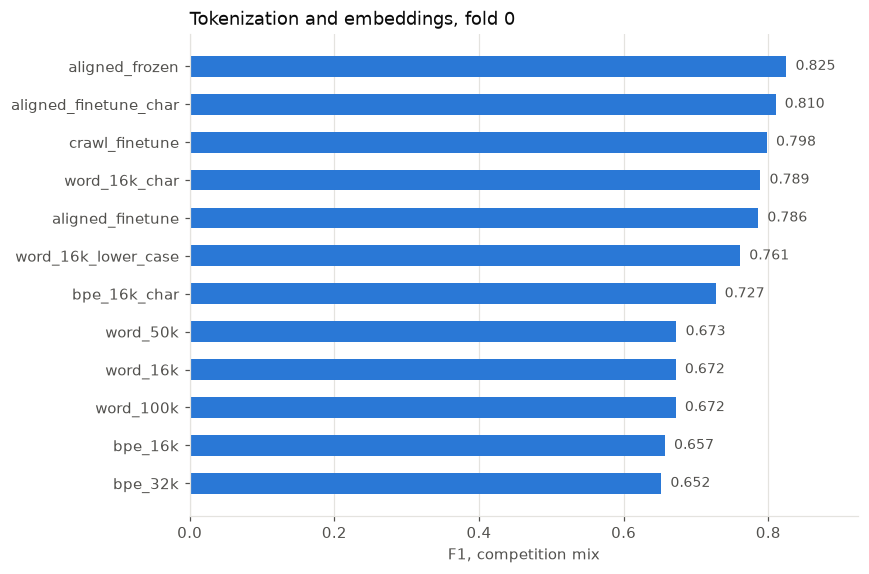

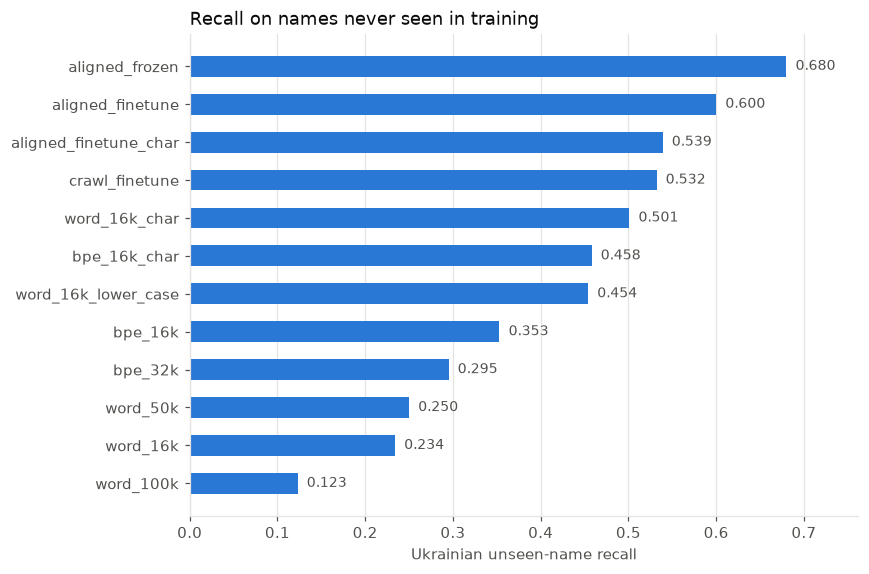

In [5]:
summary = summarize(NOTEBOOK, baseline="word_16k")
display(summary)
plots.scores_chart(summary, "Tokenization and embeddings, fold 0");
plots.scores_chart(summary, "Recall on names never seen in training", column="uk_unseen_recall", label="Ukrainian unseen-name recall");

## 4. Repeat the top three with more seeds
This shows whether the order survives a different random start.

aligned_frozen: already finished, F1 mix 0.825
aligned_frozen: F1 mix 0.841, uk 0.831, ru 0.908, 128 s on cpu
aligned_frozen: F1 mix 0.830, uk 0.819, ru 0.907, 122 s on cpu
aligned_finetune_char: already finished, F1 mix 0.810
aligned_finetune_char: F1 mix 0.804, uk 0.793, ru 0.878, 191 s on cpu
aligned_finetune_char: F1 mix 0.808, uk 0.798, ru 0.871, 184 s on cpu
crawl_finetune: already finished, F1 mix 0.798
crawl_finetune: F1 mix 0.779, uk 0.768, ru 0.852, 156 s on cpu
crawl_finetune: F1 mix 0.777, uk 0.766, ru 0.853, 136 s on cpu


,runs,vs_baseline,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,,
aligned_frozen,3,0.161,0.832,0.016,0.822,0.906,0.799,0.869,0.673,0.820,0.579,2.058
aligned_finetune_char,3,0.135,0.807,0.006,0.797,0.878,0.789,0.827,0.589,0.807,0.521,3.144
crawl_finetune,3,0.113,0.785,0.021,0.774,0.861,0.763,0.808,0.563,0.790,0.523,2.379


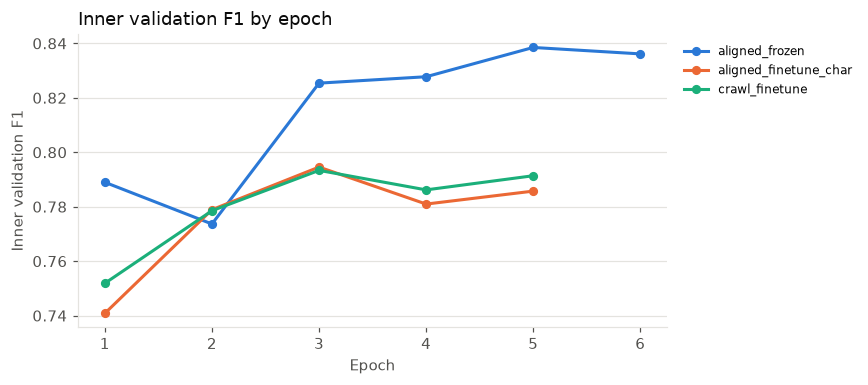

In [6]:
best = top_names(NOTEBOOK, 3)
run_grid(NOTEBOOK, {name: EXPERIMENTS[name] for name in best}, seeds=SEEDS)
display(summarize(NOTEBOOK, baseline="word_16k").loc[best])
plots.learning_curves(records_named(NOTEBOOK, best), title="Inner validation F1 by epoch");

## 5. Follow-up: does a character encoder still help with frozen vectors?
Section 3 tested characters with fine-tuned vectors (`aligned_finetune_char`), and frozen vectors without characters (`aligned_frozen`), but never the two together. This one new run closes that gap, with three seeds.

In [7]:
FOLLOW_UP = {
    "aligned_frozen_char": dict(pretrained="aligned", embedding_mode="frozen", char_hidden=32, **PRETRAINED),
}
run_grid(NOTEBOOK, FOLLOW_UP, seeds=SEEDS)
display(summarize(NOTEBOOK, baseline="word_16k").loc[["aligned_frozen", "aligned_frozen_char"]])

aligned_frozen_char: F1 mix 0.835, uk 0.823, ru 0.916, 185 s on cpu
aligned_frozen_char: F1 mix 0.787, uk 0.775, ru 0.874, 100 s on cpu
aligned_frozen_char: F1 mix 0.818, uk 0.806, ru 0.900, 184 s on cpu


,runs,vs_baseline,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,,
aligned_frozen,3,0.161,0.832,0.016,0.822,0.906,0.799,0.869,0.673,0.82,0.579,2.058
aligned_frozen_char,3,0.142,0.813,0.047,0.801,0.897,0.767,0.866,0.682,0.80,0.509,2.610


## Results summary (fold 0, 20k rows per language)

Scores are F1 mix, the held-out fold weighted 90/10 like the test set. One seed unless noted. The three-seed repeats vary by 0.006 to 0.021, so differences under about 0.02 are ties.

### The ladder, from baseline to best

| Step | Run | F1 mix | Ukrainian unseen-name recall |
| --- | --- | ---: | ---: |
| Baseline: 16k words | `word_16k` | 0.672 | 0.234 |
| + lowercase and a capitalization feature | `word_16k_lower_case` | 0.761 | 0.454 |
| + a character encoder instead | `word_16k_char` | 0.789 | 0.501 |
| + frozen fastText aligned vectors (3 seeds) | `aligned_frozen` | **0.832** | **0.673** |

### What we learned

1. **Vocabulary size alone does nothing.** 16k, 50k and 100k words tie (0.672, 0.673, 0.672). At 100k, unseen-name recall falls to 0.123. A likely reason, not tested: with a large list, rare words get their own embedding rows that stay random because the labeled rows never contain them, while with 16k those words all become `[UNK]`, which the model learns to treat as a hint for a location.
2. **BPE loses to words, as in the EDA.** 0.657 and 0.652 against 0.672. It finds more unseen names (recall 0.353 against 0.234) but its precision is lower (0.623 against 0.713), so it predicts extra pieces. With a character encoder, the gap is 0.727 against 0.789. A larger BPE vocabulary doesn't help.
3. **Spelling information is worth a lot.** Case information gives +0.09 and a character encoder +0.117, with no pretrained data. Both mostly help unseen names. A likely reason, not tested: every unknown word is the same `[UNK]` token, and capitalization or spelling lets the model see that a capitalized unknown word is probably a place. We didn't test lowercasing and the case feature separately.
4. **Pretrained fastText gives the biggest gain.** +0.16 in F1 mix, and unseen-name recall of 0.673. Unknown labeled mentions fall from about 40% to 7%, and unknown competition-post words from 30% to 9%.
5. **Aligned beats crawl, and frozen beats fine-tuning.** Aligned (0.832, 3 seeds) is ahead of crawl (0.785). Frozen is ahead of fine-tuned (0.807 with characters, 3 seeds). A likely reason, not tested: fine-tuning on only 20k rows moves the vectors of frequent words but not rare ones, so the two kinds of words stop sharing one space. Frozen vectors have only about 0.3M trainable weights, so the model is limited by data, not size.
6. **The competition-style checks moved the same way.** The synthetic-post F1 rose from 0.656 to 0.820, which is encouraging. The 26-post F1 rose from 0.317 to about 0.58, but it varies from 0.527 to 0.610 across seeds of the same setup, so it's too noisy to choose between options.

### Decisions for `nerkit/decisions.py`

```python
"tokenizer": "word", "vocab_size": 16_000, "lowercase": True, "case_feature": True,
"pretrained": "aligned", "embedding_mode": "frozen", "pretrained_top_k": 200_000,
```

**Follow-up result (section 5, 3 seeds):** a character encoder on top of frozen vectors scored 0.813 against 0.832 without it, inside the seed spread, and one run stopped after 3 epochs. It adds nothing here, so `char_hidden` stays 0. These settings are now in `decisions.py`, together with `max_epochs=10`.

### Caveats

- Every pretrained run also used lowercase and the case feature, so the +0.16 includes them. Compared with `word_16k_lower_case`, pretrained vectors add about +0.07.
- This is one fold. The winning setup will be re-checked on folds 1 and 2 in notebook 02, when its finalists are confirmed.
- Many runs stopped at the 6-epoch limit, so some may still be improving. Notebook 03 allows 10 epochs.
- Better validation scores don't guarantee a better leaderboard score, since the competition posts are different text. A leaderboard check of the best setup would be informative.